# Batch prioritization of quote requests

A fictional B2B company receives quote requests every day. Some customers buy on their own within a few days;
the sales team has limited time and should spend it elsewhere. The model ranks each day's requests by the
probability of converting **on their own within 5 days**. The team skips the top of the list and works
the rest, so the metrics measure how well the top identifies those natural conversions.

All data is synthetic (`scripts/generate_data.py`). The logic lives in `src/batch_prioritization/`; this
notebook runs it and explains the results.

| | Definition |
|---|---|
| **Unit** | One quote request. |
| **Label** | 1 if the request converted within 5 days of being made, else 0. |
| **Population** | Requests whose 5-day window had closed by the extraction date (2026-01-01). |
| **Split** | Train until 2025-06, validation 2025-07 to 2025-09, test 2025-10 to 2025-12, with a 5-day gap before each boundary. |
| **History features** | Only conversions that happened *before* the request being scored. |

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

if not (ROOT / "data" / "raw" / "quote_requests.csv").exists():
    subprocess.run([sys.executable, str(ROOT / "scripts" / "generate_data.py")], check=True)

## 1. Data, labels and split

In [2]:
from pyspark.sql import functions as F

from batch_prioritization.data import load_customers, load_requests
from batch_prioritization.features import build_history_features
from batch_prioritization.leaky import leaky_history_features
from batch_prioritization.spark import get_spark
from batch_prioritization.train import build_dataset
from batch_prioritization.split import time_split

spark = get_spark()
spark.sparkContext.setLogLevel("ERROR")

requests = load_requests(spark)
data = build_dataset(spark)
train, valid, test = time_split(data)

print(f"Requests: {requests.count():,}   labelled: {data.count():,}")
for name, df in [("train", train), ("valid", valid), ("test", test)]:
    r = df.agg(F.count("*").alias("n"), F.avg("label").alias("rate"), F.min("requested_at"), F.max("requested_at")).first()
    print(f"{name:<6} n={r['n']:>6,}  converts in 5 days={r['rate']:.1%}  from {r[2]:%Y-%m-%d} to {r[3]:%Y-%m-%d}")

Requests: 46,805   labelled: 46,432
train  n=31,869  converts in 5 days=22.0%  from 2024-01-01 to 2025-06-26
valid  n= 6,682  converts in 5 days=25.5%  from 2025-07-01 to 2025-09-26


test   n= 7,106  converts in 5 days=25.2%  from 2025-10-01 to 2025-12-27


## 2. The leakage in the original logic

The original notebook counted every earlier conversion of the customer, even if it happened *after* the request
being scored. How many requests does that affect?

In [3]:
honest = build_history_features(requests).select("request_id", F.col("prior_known_conversion_count").alias("honest"))
leaky = leaky_history_features(requests).select("request_id", F.col("prior_known_conversion_count").alias("leaky"))
cmp = honest.join(leaky, "request_id")
n_affected = cmp.filter(F.col("leaky") > F.col("honest")).count()
print(f"Requests where the original logic counts a conversion not yet known: {n_affected:,} ({n_affected / requests.count():.1%})")

Requests where the original logic counts a conversion not yet known: 7,102 (15.2%)


## 3. Train and evaluate

`batch_prioritization.train` fits every model on the same splits, logs each run to a local MLflow store
and writes `reports/metrics.json`:

- **naive**: the customer's historical conversion rate, no model;
- **no_history**: gradient-boosted trees on the request attributes only;
- **full**: gradient-boosted trees on request attributes + leakage-free history;
- **leaky_demo**: the same model with the original, leaky history (not a candidate).

In [4]:
from batch_prioritization import train as train_module

train_module.main()  # also stops the Spark session
metrics = json.loads((ROOT / "reports" / "metrics.json").read_text())

train=31869  valid=6682  test=7106
model       split        n   base    ROC     PR  prec@10  capt@10  capt@20
naive       valid     6682  0.255  0.666  0.374    0.439    0.172    0.326
naive       test      7106  0.252  0.674  0.368    0.415    0.165    0.320
no_history  valid     6682  0.255  0.559  0.288    0.312    0.123    0.243
no_history  test      7106  0.252  0.575  0.302    0.346    0.138    0.257
full        valid     6682  0.255  0.678  0.384    0.442    0.174    0.328
full        test      7106  0.252  0.667  0.361    0.408    0.162    0.304
leaky_demo  valid     6682  0.255  0.675  0.372    0.423    0.166    0.328
leaky_demo  test      7106  0.252  0.669  0.357    0.390    0.155    0.303


In [5]:
import pandas as pd

rows = []
for model, r in metrics["results"].items():
    for split, m in r["metrics"].items():
        rows.append({"model": model, "split": split, **m})
table = pd.DataFrame(rows).set_index(["model", "split"])
table[["n", "base_rate", "roc_auc", "pr_auc", "precision_top10", "capture_top10", "capture_top20"]].round(3)

n  base_rate  roc_auc  pr_auc  precision_top10  \
model      split                                                      
naive      valid  6682      0.255    0.666   0.374            0.439   
           test   7106      0.252    0.674   0.368            0.415   
no_history valid  6682      0.255    0.559   0.288            0.312   
           test   7106      0.252    0.575   0.302            0.346   
full       valid  6682      0.255    0.678   0.384            0.442   
           test   7106      0.252    0.667   0.361            0.408   
leaky_demo valid  6682      0.255    0.675   0.372            0.423   
           test   7106      0.252    0.669   0.357            0.390   

                  capture_top10  capture_top20  
model      split                                
naive      valid          0.172          0.326  
           test           0.165          0.320  
no_history valid          0.123          0.243  
           test           0.138          0.257  
full       valid          0.174          0.328  
           test           0.162          0.304  
leaky_demo valid          0.166          0.328  
           test           0.155          0.303

## 4. Ranking quality on the test period

Lift by decile (decile 1 = highest scores) and the share of all conversions captured when working the list
from the top.

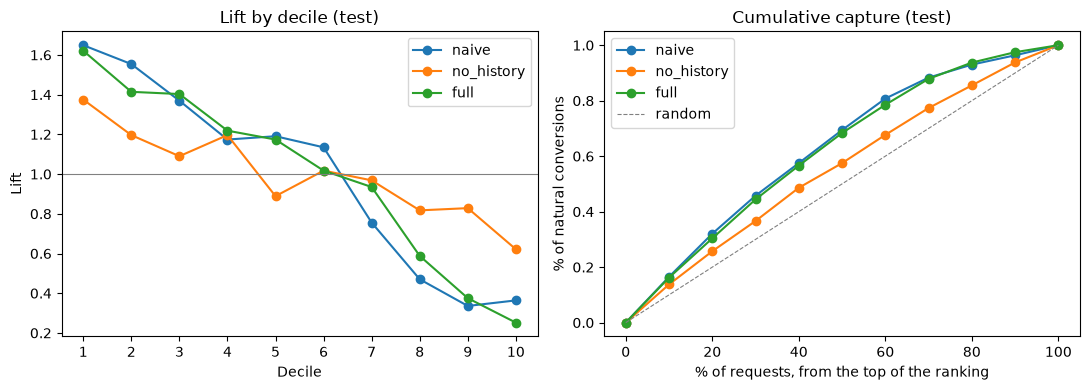

In [6]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for model in ["naive", "no_history", "full"]:
    d = pd.DataFrame(metrics["results"][model]["test_deciles"])
    ax1.plot(d["decile"], d["lift"], marker="o", label=model)
    captured = (d["conversion_rate"] * d["n"]).cumsum() / (d["conversion_rate"] * d["n"]).sum()
    ax2.plot([0] + list(d["decile"] * 10), [0] + list(captured), marker="o", label=model)
ax1.axhline(1, color="grey", lw=0.8)
ax1.set(title="Lift by decile (test)", xlabel="Decile", ylabel="Lift", xticks=range(1, 11))
ax2.plot([0, 100], [0, 1], color="grey", lw=0.8, ls="--", label="random")
ax2.set(title="Cumulative capture (test)", xlabel="% of requests, from the top of the ranking", ylabel="% of natural conversions")
ax1.legend(); ax2.legend()
plt.tight_layout()
plt.show()

## 5. What the results say

- **History carries the signal.** The model without history is clearly weaker than any model that knows the
  customer's past.
- **The gradient-boosted model does not beat the naive rule.** On validation and test both rank requests
  almost equally well. In this data the request attributes add little on top of the customer's history, so the
  simple rule would be the one to deploy: it is cheaper, explainable and as good. This is why every model
  here is compared against a naive baseline before anything else.
- **The leakage fix barely moves the metrics here, and is still required.** The original logic touches the
  share of requests shown in section 2, yet on this synthetic data the leaky model scores about the same as
  the honest one (compare `leaky_demo` and `full` in the table). That is a property of this data, not a
  reason to keep the leak: on real data the effect depends on how often outcomes arrive after the next
  request, and a leaky model can look better in evaluation and then degrade in production. The fix and its
  tests guarantee the model never uses information it would not have at scoring time.
- **Small differences are noise.** Differences of a few thousandths of AUC between models are within the
  variation you would see from a different seed or period; the ranking of naive ≈ full > no_history is the
  stable result.
- **Limits.** The data is synthetic and the effects are moderate by design. The 5-day window and the split
  dates are parameters in `src/batch_prioritization/config.py`.